# 07 目标检测：真正学习类别与边界框

本课从零训练一个单目标检测器：输入 32×32 RGB 图，输出类别和归一化边界框 `[xmin,ymin,xmax,ymax]`。
训练图像为程序生成的圆或方块，每张恰好一个目标；这让初学者能看懂所有标注和学习过程。
它不是 YOLO，也不能直接用于真实街景，但确实通过损失函数学习分类与定位，而不是把轮廓查找冒充深度检测。


In [1]:
from pathlib import Path
import sys, os
for folder in [Path.cwd(), *Path.cwd().parents]:
    if (folder / "course_utils.py").exists():
        sys.path.insert(0, str(folder)); break
else:
    raise FileNotFoundError("请从课程项目根目录或 notebooks 目录启动 Jupyter。")
from course_utils import setup, device, save_figure
ROOT = setup(seed=42)
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    pass
import numpy as np
import matplotlib.pyplot as plt
import cv2
import torch
from torch import nn
torch.set_num_threads(min(2, os.cpu_count() or 1))
DEVICE = device()
print("计算设备：", DEVICE)


计算设备： cpu


## 1. 生成独立的训练、验证、测试样本

框坐标归一化到 0–1。颜色、尺寸、位置、背景噪声随机变化；标签由生成时的几何参数给定。
三个集合使用不同随机种子，绝不把测试图像用于训练。

下面的数组按 **NCHW** 存放：`N` 是图片张数，`C=3` 对应红、绿、蓝通道，`H=W=32` 是高和宽。
`train_X[0,0,10:14,10:14]` 是第 1 张图红通道的一块 4×4 像素矩阵；数值为 0–1，越大表示该通道越亮。
类别标签形状为 `[N]`，`0` 表示方块、`1` 表示圆。框标签是 `[N,4]`，每行依次是左上角 `xmin,ymin` 和右下角 `xmax,ymax`。
例如 `[0.25,0.25,0.75,0.75] × 32 = [8,8,24,24]`，表示图片中从 `(8,8)` 到 `(24,24)` 的框；横坐标向右、纵坐标向下。


输入张量： (700, 3, 32, 32) 标签： [1, 1, 1, 0]
框矩阵：
 [[0.5     0.21875 0.84375 0.5625 ]
 [0.34375 0.21875 0.8125  0.6875 ]
 [0.0625  0.46875 0.40625 0.8125 ]
 [0.28125 0.3125  0.6875  0.71875]]
第一个 RGB 图的 R 通道局部：
 [[0.07 0.04 0.1  0.05]
 [0.06 0.03 0.08 0.06]
 [0.05 0.08 0.07 0.04]
 [0.08 0.03 0.08 0.09]]


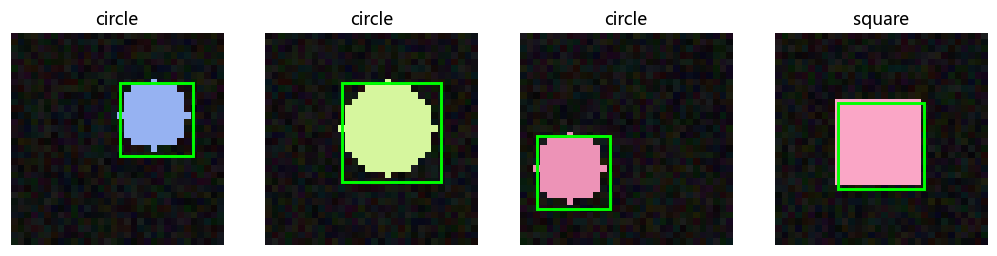

WindowsPath('D:/workspace/cv/cv-beginner-course/outputs/07_detection_inputs.png')

In [2]:
from torch.utils.data import DataLoader, TensorDataset
def make_detection_data(n,seed):
    rng = np.random.default_rng(seed)
    ims, labels, boxes = [],[],[]
    for _ in range(n):
        im = rng.uniform(.02,.12,(32,32,3)).astype(np.float32)
        size = 2*int(rng.integers(4,8))+1; x = int(rng.integers(2,30-size)); y0 = int(rng.integers(2,30-size))
        label = int(rng.integers(0,2)); color = rng.uniform(.55,1.,3).tolist()
        if label == 0:
            cv2.rectangle(im,(x,y0),(x+size-1,y0+size-1),color,-1)
        else:
            cv2.circle(im,(x+size//2,y0+size//2),size//2,color,-1)
        ims.append(im.transpose(2,0,1)); labels.append(label)
        boxes.append([x/32,y0/32,(x+size)/32,(y0+size)/32])
    return torch.tensor(np.array(ims)),torch.tensor(labels),torch.tensor(boxes,dtype=torch.float32)
train_X,train_y,train_box = make_detection_data(700,10)
val_X,val_y,val_box = make_detection_data(120,20)
test_X,test_y,test_box = make_detection_data(120,30)
names = ["square","circle"]
print("输入张量：",tuple(train_X.shape),"标签：",train_y[:4].tolist())
print("框矩阵：\n",train_box[:4].numpy())
print("第一个 RGB 图的 R 通道局部：\n",np.round(train_X[0,0,10:14,10:14].numpy(),2))
def draw_box(ax, box, color, label):
    x1,y1,x2,y2 = np.asarray(box)*32
    ax.add_patch(plt.Rectangle((x1,y1),x2-x1,y2-y1,fill=False,ec=color,lw=2,label=label))
fig,axs=plt.subplots(1,4,figsize=(12,3))
for i,ax in enumerate(axs):
    ax.imshow(train_X[i].permute(1,2,0)); draw_box(ax,train_box[i],"lime","ground truth")
    ax.set_title(names[train_y[i]]); ax.axis("off")
save_figure("07_detection_inputs.png")


## 2. 一个共享特征骨干，两个预测分支

卷积提取空间特征。分类头输出 2 个 logits；定位头预测中心与宽高，再转为 `xyxy`。
框回归损失使用 Smooth L1；分类使用交叉熵。这里固定每张一个物体，所以无需候选框匹配或 NMS。

模型的两项输出分别是 `[N,2]` 的类别 **logits**（每张图两个未归一化分数）和 `[N,4]` 的预测框。
对 logits 按类别维做 `argmax(dim=1)` 得到 `[N]` 的预测类别；需要概率时才做 `softmax(dim=1)`，不能把原始分数直接当作概率。


In [3]:
class SingleObjectDetector(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(nn.Conv2d(3,12,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),
                                      nn.Conv2d(12,20,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),nn.Flatten(),
                                      nn.Linear(20*8*8,64),nn.ReLU())
        self.class_head=nn.Linear(64,2); self.box_head=nn.Linear(64,4)
    def forward(self,x):
        f=self.features(x); raw=self.box_head(f).sigmoid()
        center=.15+.7*raw[:,:2]; wh=.15+.45*raw[:,2:]
        box=torch.cat([center-wh/2,center+wh/2],dim=1)
        return self.class_head(f),box
model=SingleObjectDetector().to(DEVICE)
optimizer=torch.optim.Adam(model.parameters(),lr=.002)
loader=DataLoader(TensorDataset(train_X,train_y,train_box),batch_size=64,shuffle=True,num_workers=0)
def box_iou(a,b):
    lo=torch.maximum(a[:,:2],b[:,:2]); hi=torch.minimum(a[:,2:],b[:,2:])
    intersection=(hi-lo).clamp(min=0).prod(1)
    area_a=(a[:,2:]-a[:,:2]).clamp(min=0).prod(1)
    area_b=(b[:,2:]-b[:,:2]).clamp(min=0).prod(1)
    return intersection/(area_a+area_b-intersection+1e-8)
print("模型输出形状：",[tuple(v.shape) for v in model(train_X[:2].to(DEVICE))])


模型输出形状： [(2, 2), (2, 4)]


## 3. 学习分类与定位

损失为 `分类交叉熵 + 10 × SmoothL1(预测框,真值框)`，权重只适用于本教学例。
按验证集“类别正确且 IoU≥0.5”的比例选择模型；测试集仍未使用。


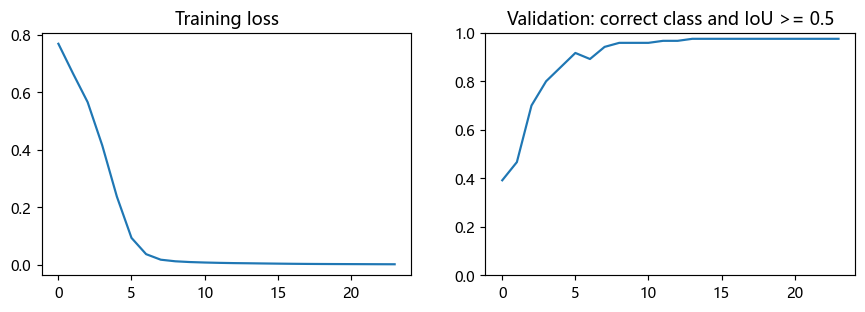

最佳验证成功率： 0.975


In [4]:
import copy
history=[]; best_score=-1.; best_state=None
for epoch in range(24):
    model.train(); loss_sum=0.
    for xb,yb,bb in loader:
        xb,yb,bb=xb.to(DEVICE),yb.to(DEVICE),bb.to(DEVICE)
        cls,box=model(xb)
        loss=nn.functional.cross_entropy(cls,yb)+10*nn.functional.smooth_l1_loss(box,bb)
        optimizer.zero_grad(); loss.backward(); optimizer.step(); loss_sum+=loss.item()*len(xb)
    model.eval()
    with torch.no_grad():
        cls,box=model(val_X.to(DEVICE)); iou=box_iou(box,val_box.to(DEVICE))
        score=((cls.argmax(1)==val_y.to(DEVICE)) & (iou>=.5)).float().mean().item()
    history.append((loss_sum/len(train_X),score))
    if score>best_score: best_score=score; best_state=copy.deepcopy(model.state_dict())
model.load_state_dict(best_state)
fig,axs=plt.subplots(1,2,figsize=(10,3))
axs[0].plot(np.array(history)[:,0]); axs[0].set_title("Training loss")
axs[1].plot(np.array(history)[:,1]); axs[1].set_title("Validation: correct class and IoU >= 0.5"); axs[1].set_ylim(0,1)
save_figure("07_detection_training.png")
print("最佳验证成功率：",round(best_score,3))


## 4. 独立评价与可视化

IoU 是交并比：预测框与真值框交集面积 / 并集面积。下面报告类别准确率、平均 IoU 和定位成功率。
这些是单目标教学指标，**不是 COCO mAP**；完整多目标 mAP 需要按置信度排序、类别、IoU 阈值与一对一匹配计算 PR 曲线。


类别准确率=1.000，平均 IoU=0.760，正确类别且 IoU≥0.5=0.958
真值框： [0.21875 0.3125  0.625   0.71875] 预测框： [0.203 0.335 0.602 0.729]


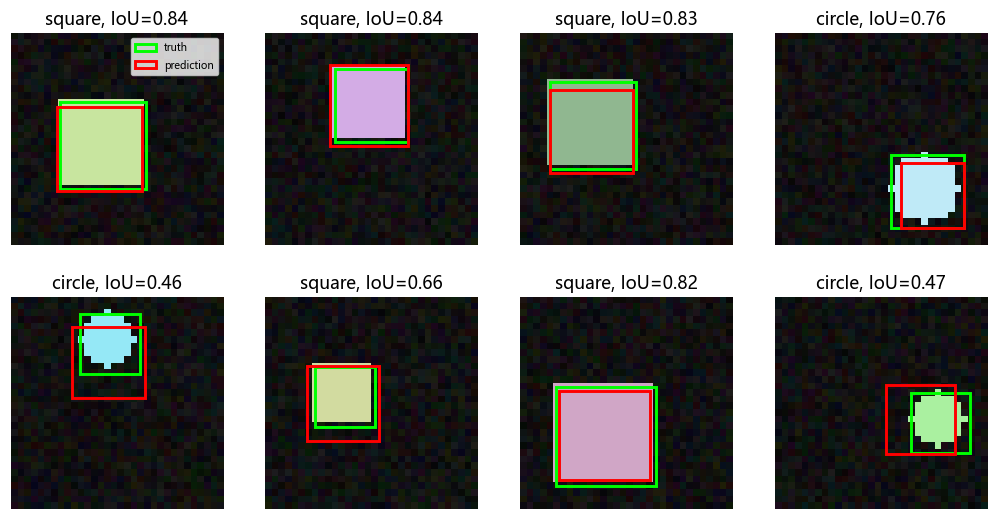

In [5]:
model.eval()
with torch.no_grad():
    logits,pred_box=model(test_X.to(DEVICE)); pred_class=logits.argmax(1).cpu()
    pred_box=pred_box.cpu(); ious=box_iou(pred_box,test_box)
accuracy=(pred_class==test_y).float().mean().item()
success=((pred_class==test_y)&(ious>=.5)).float().mean().item()
print(f"类别准确率={accuracy:.3f}，平均 IoU={ious.mean():.3f}，正确类别且 IoU≥0.5={success:.3f}")
print("真值框：",test_box[0].numpy(),"预测框：",np.round(pred_box[0].numpy(),3))
fig,axs=plt.subplots(2,4,figsize=(12,6))
for i,ax in enumerate(axs.flat):
    ax.imshow(test_X[i].permute(1,2,0)); draw_box(ax,test_box[i],"lime","truth"); draw_box(ax,pred_box[i],"red","prediction")
    ax.set_title(f"{names[pred_class[i]]}, IoU={ious[i]:.2f}"); ax.axis("off")
axs[0,0].legend(fontsize=7)
save_figure("07_detection_results.png")
assert ious.mean()>.5 and accuracy>.8,"模型未学会基础任务：检查训练与数据。"


## 5. 挑出最差结果，认识任务边界

每张只允许一个目标这一假设非常强。真实检测还需要处理背景、多个目标、遮挡、小目标和标签缺失。
以下按 IoU 最差排序，而不是只挑最好看的图。


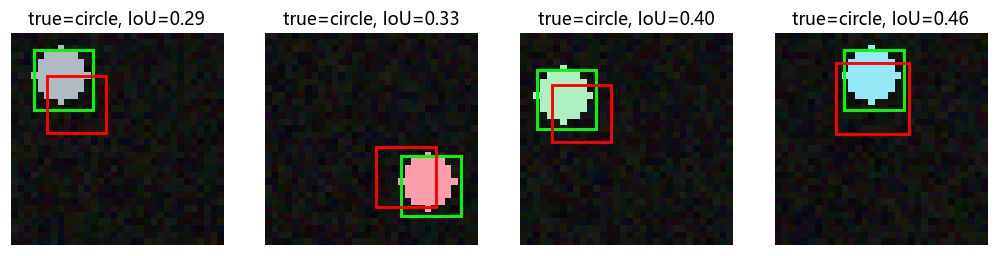

WindowsPath('D:/workspace/cv/cv-beginner-course/outputs/07_detection_failures.png')

In [6]:
worst=torch.argsort(ious)[:4]
fig,axs=plt.subplots(1,4,figsize=(12,3))
for ax,k in zip(axs,worst):
    ax.imshow(test_X[k].permute(1,2,0)); draw_box(ax,test_box[k],"lime","truth"); draw_box(ax,pred_box[k],"red","prediction")
    ax.set_title(f"true={names[test_y[k]]}, IoU={ious[k]:.2f}"); ax.axis("off")
save_figure("07_detection_failures.png")


## 6. 练习与后续真实数据路线

练习：增加背景纹理；让物体触及边缘；生成含两物体的图，观察本模型为何无法正确表达两个框。
下一步参考 TorchVision Faster R-CNN 教程，把样本改成 `image + {boxes,labels}`，使用自己标注的数据和预训练权重。

来源：[TorchVision 目标检测微调教程](https://pytorch.org/tutorials/intermediate/torchvision_tutorial.html)、[Faster R-CNN 原论文](https://arxiv.org/abs/1506.01497)、[COCO 评价实现](https://github.com/cocodataset/cocoapi)。本例为课程原创简化实现，不声称复现上述完整模型。
